In [94]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [95]:
# Import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt
# Set style & figures inline
sns.set()
%matplotlib inline

In [96]:
confirmed_cases_data_url = 'https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv'
death_cases_data_url = 'https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_deaths_global.csv'
recovery_cases_data_url = 'https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_recovered_global.csv'

In [97]:
# Import data & check it out
raw_data_confirmed = pd.read_csv(confirmed_cases_data_url)
raw_data_confirmed.drop(['Province/State'], axis = 'columns', inplace=True)
raw_data_confirmed.head()

,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,1/28/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,Albania,41.15330,20.168300,0,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,Algeria,28.03390,1.659600,0,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
3,Andorra,42.50630,1.521800,0,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
4,Angola,-11.20270,17.873900,0,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288


In [98]:
# Group by region
data_day = raw_data_confirmed.groupby(['Country/Region']).sum().drop(['Lat', 'Long'], axis=1)

data_day.head()

,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,1/28/20,1/29/20,1/30/20,1/31/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
Country/Region,,,,,,,,,,,,,,,,,,,,,
Afghanistan,0,0,0,0,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
Albania,0,0,0,0,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
Algeria,0,0,0,0,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
Andorra,0,0,0,0,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
Angola,0,0,0,0,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288


In [99]:
df = data_day.transpose()

In [100]:
# Melt data so that it is long
data = data_day.reset_index().melt(id_vars='Country/Region', var_name='date')
data.head()

,Country/Region,date,value
0,Afghanistan,1/22/20,0
1,Albania,1/22/20,0
2,Algeria,1/22/20,0
3,Andorra,1/22/20,0
4,Angola,1/22/20,0


In [101]:
data.loc[(data.value < 1),'value'] = None
data.head()
data

,Country/Region,date,value
0,Afghanistan,1/22/20,NaN
1,Albania,1/22/20,NaN
2,Algeria,1/22/20,NaN
3,Andorra,1/22/20,NaN
4,Angola,1/22/20,NaN
...,...,...,...
229738,West Bank and Gaza,3/9/23,703228.0
229739,Winter Olympics 2022,3/9/23,535.0
229740,Yemen,3/9/23,11945.0
229741,Zambia,3/9/23,343135.0


In [102]:
# Pivot data to wide & index by date
df = data.pivot(index='date', columns='Country/Region', values='value')
df.tail()

Country/Region,Afghanistan,Albania,Algeria,Andorra,Angola,Antarctica,Antigua and Barbuda,Argentina,Armenia,Australia,...,Uruguay,Uzbekistan,Vanuatu,Venezuela,Vietnam,West Bank and Gaza,Winter Olympics 2022,Yemen,Zambia,Zimbabwe
date,,,,,,,,,,,,,,,,,,,,,
9/8/21,153736.0,153318.0,198962.0,15070.0,49349.0,NaN,1974.0,5215332.0,246410.0,68042.0,...,386082.0,161768.0,4.0,342148.0,563676.0,361881.0,NaN,8230.0,207442.0,125931.0
9/8/22,195298.0,330687.0,270507.0,46113.0,102636.0,11.0,8974.0,9689861.0,436727.0,10111190.0,...,981186.0,243893.0,11902.0,543204.0,11431823.0,702591.0,535.0,11932.0,333180.0,256834.0
9/9/20,38630.0,10704.0,47216.0,1301.0,3092.0,NaN,95.0,512293.0,45152.0,26524.0,...,1741.0,44930.0,NaN,56751.0,1059.0,27919.0,NaN,1999.0,13112.0,7429.0
9/9/21,153840.0,154316.0,199275.0,15078.0,49628.0,NaN,2059.0,5218993.0,246997.0,69912.0,...,386258.0,162421.0,4.0,344297.0,576096.0,364364.0,NaN,8267.0,207560.0,126056.0
9/9/22,195471.0,330842.0,270522.0,46113.0,103131.0,11.0,8974.0,9689861.0,436727.0,10111728.0,...,981186.0,243893.0,11908.0,543204.0,11435472.0,702591.0,535.0,11932.0,333204.0,256859.0


In [103]:
# Set index as DateTimeIndex
datetime_index = pd.DatetimeIndex(df.index)
df.set_index(datetime_index, inplace=True)
df.head()

Country/Region,Afghanistan,Albania,Algeria,Andorra,Angola,Antarctica,Antigua and Barbuda,Argentina,Armenia,Australia,...,Uruguay,Uzbekistan,Vanuatu,Venezuela,Vietnam,West Bank and Gaza,Winter Olympics 2022,Yemen,Zambia,Zimbabwe
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,52513.0,58316.0,99897.0,8117.0,17568.0,NaN,159.0,1629594.0,159738.0,28460.0,...,19753.0,77182.0,1.0,113884.0,1474.0,139223.0,NaN,2101.0,20997.0,14084.0
2022-01-01,158107.0,210224.0,218818.0,23740.0,82398.0,11.0,4283.0,5674428.0,344980.0,462955.0,...,414294.0,199030.0,7.0,444828.0,1746092.0,469748.0,NaN,10127.0,257948.0,214214.0
2023-01-01,207616.0,333811.0,271229.0,47751.0,105095.0,11.0,9106.0,9891139.0,445976.0,11132933.0,...,1011988.0,249217.0,12013.0,550613.0,11525284.0,703228.0,535.0,11945.0,334629.0,259981.0
2021-01-10,53489.0,63595.0,102144.0,8586.0,18193.0,NaN,176.0,1722217.0,162131.0,28614.0,...,26186.0,77572.0,1.0,116610.0,1514.0,147400.0,NaN,2104.0,27728.0,21477.0
2022-01-10,158394.0,220487.0,222639.0,27983.0,90316.0,11.0,5058.0,6399196.0,345981.0,1139097.0,...,456179.0,200730.0,7.0,447288.0,1914393.0,472910.0,NaN,10197.0,284389.0,223000.0


In [104]:
# Check out index
df.index
df

Country/Region,Afghanistan,Albania,Algeria,Andorra,Angola,Antarctica,Antigua and Barbuda,Argentina,Armenia,Australia,...,Uruguay,Uzbekistan,Vanuatu,Venezuela,Vietnam,West Bank and Gaza,Winter Olympics 2022,Yemen,Zambia,Zimbabwe
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,52513.0,58316.0,99897.0,8117.0,17568.0,NaN,159.0,1629594.0,159738.0,28460.0,...,19753.0,77182.0,1.0,113884.0,1474.0,139223.0,NaN,2101.0,20997.0,14084.0
2022-01-01,158107.0,210224.0,218818.0,23740.0,82398.0,11.0,4283.0,5674428.0,344980.0,462955.0,...,414294.0,199030.0,7.0,444828.0,1746092.0,469748.0,NaN,10127.0,257948.0,214214.0
2023-01-01,207616.0,333811.0,271229.0,47751.0,105095.0,11.0,9106.0,9891139.0,445976.0,11132933.0,...,1011988.0,249217.0,12013.0,550613.0,11525284.0,703228.0,535.0,11945.0,334629.0,259981.0
2021-01-10,53489.0,63595.0,102144.0,8586.0,18193.0,NaN,176.0,1722217.0,162131.0,28614.0,...,26186.0,77572.0,1.0,116610.0,1514.0,147400.0,NaN,2104.0,27728.0,21477.0
2022-01-10,158394.0,220487.0,222639.0,27983.0,90316.0,11.0,5058.0,6399196.0,345981.0,1139097.0,...,456179.0,200730.0,7.0,447288.0,1914393.0,472910.0,NaN,10197.0,284389.0,223000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-09-08,153736.0,153318.0,198962.0,15070.0,49349.0,NaN,1974.0,5215332.0,246410.0,68042.0,...,386082.0,161768.0,4.0,342148.0,563676.0,361881.0,NaN,8230.0,207442.0,125931.0
2022-09-08,195298.0,330687.0,270507.0,46113.0,102636.0,11.0,8974.0,9689861.0,436727.0,10111190.0,...,981186.0,243893.0,11902.0,543204.0,11431823.0,702591.0,535.0,11932.0,333180.0,256834.0
2020-09-09,38630.0,10704.0,47216.0,1301.0,3092.0,NaN,95.0,512293.0,45152.0,26524.0,...,1741.0,44930.0,NaN,56751.0,1059.0,27919.0,NaN,1999.0,13112.0,7429.0


In [105]:
country = "Philippines"
country_data = df[[country]].dropna() 
country_data_eda = df[[country]].dropna()
country_data.head()
country_data.tail()

Country/Region,Philippines
date,
2021-09-08,2134005.0
2022-09-08,3898882.0
2020-09-09,245143.0
2021-09-09,2161892.0
2022-09-09,3901033.0


In [106]:
#Dataset Overview
print("Dataset Overview:")
print(country_data_eda.head())
print("\nDataset Info:")
print(country_data_eda.info())
print("\nSummary Statistics:")
print(country_data_eda.describe())

Dataset Overview:
Country/Region  Philippines
date                       
2021-01-01         475820.0
2022-01-01        2847486.0
2023-01-01        4064779.0
2021-01-10         487690.0
2022-01-10        2998530.0

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1135 entries, 2021-01-01 to 2022-09-09
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Philippines  1135 non-null   float64
dtypes: float64(1)
memory usage: 17.7 KB
None

Summary Statistics:
Country/Region   Philippines
count           1.135000e+03
mean            2.010253e+06
std             1.605366e+06
min             1.000000e+00
25%             3.974220e+05
50%             1.791003e+06
75%             3.690352e+06
max             4.077452e+06


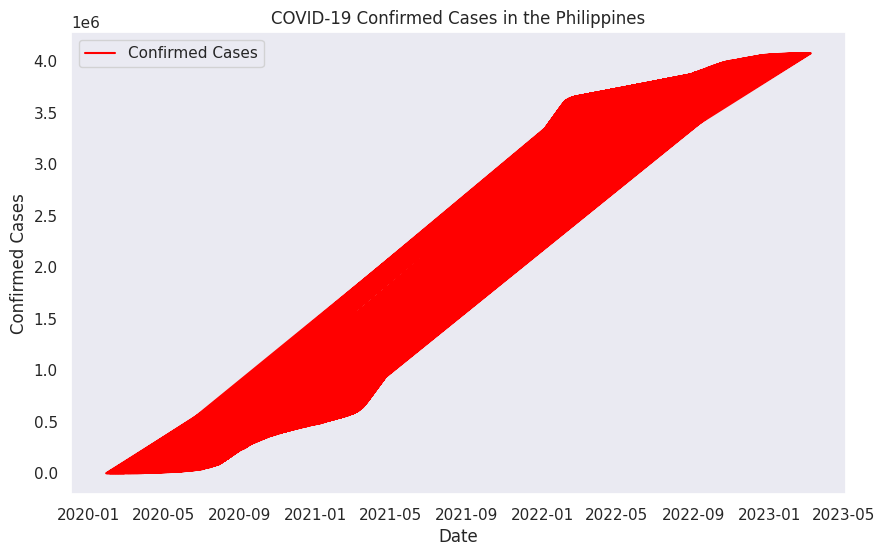

In [107]:
#Time Series Visualization
plt.figure(figsize=(10, 6))
plt.plot(country_data_eda, label="Confirmed Cases", color="Red")
plt.title("COVID-19 Confirmed Cases in the Philippines")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.legend()
plt.grid()
plt.show()

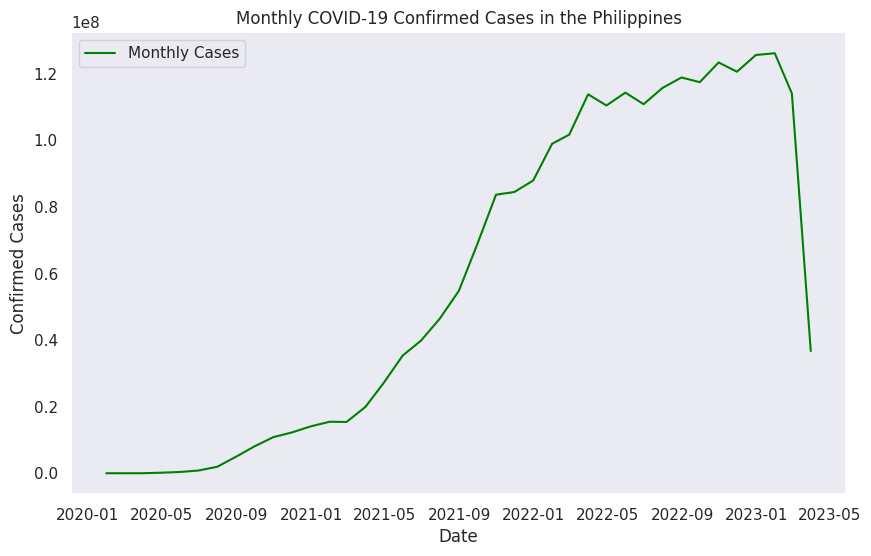

In [108]:
#Monthly Aggregation and Visualization
country_data_monthly = country_data_eda.resample("ME").sum()  # Monthly aggregation
plt.figure(figsize=(10, 6))
plt.plot(country_data_monthly, label="Monthly Cases", color="green")
plt.title("Monthly COVID-19 Confirmed Cases in the Philippines")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.legend()
plt.grid()
plt.show()

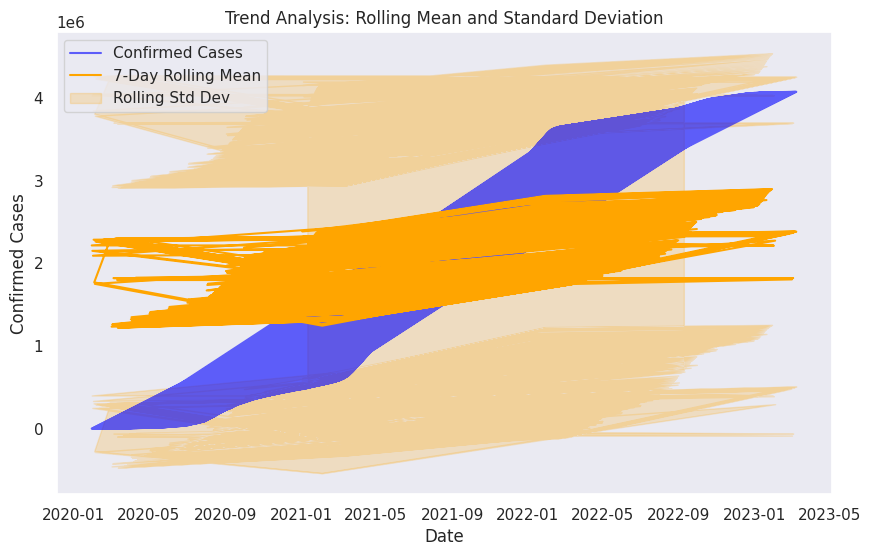

In [109]:
#Rolling Statistics (Trend Analysis)
rolling_window = 7  # Weekly average
country_data_eda["Rolling Mean"] = country_data_eda["Philippines"].rolling(window=rolling_window).mean()
country_data_eda["Rolling Std"] = country_data_eda["Philippines"].rolling(window=rolling_window).std()

plt.figure(figsize=(10, 6))
plt.plot(country_data_eda["Philippines"], label="Confirmed Cases", color="blue", alpha=0.6)
plt.plot(country_data_eda["Rolling Mean"], label=f"{rolling_window}-Day Rolling Mean", color="orange")
plt.fill_between(
    country_data_eda.index,
    country_data_eda["Rolling Mean"] - country_data_eda["Rolling Std"],
    country_data_eda["Rolling Mean"] + country_data_eda["Rolling Std"],
    color="orange",
    alpha=0.2,
    label="Rolling Std Dev",
)
plt.title("Trend Analysis: Rolling Mean and Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.legend()
plt.grid()
plt.show()

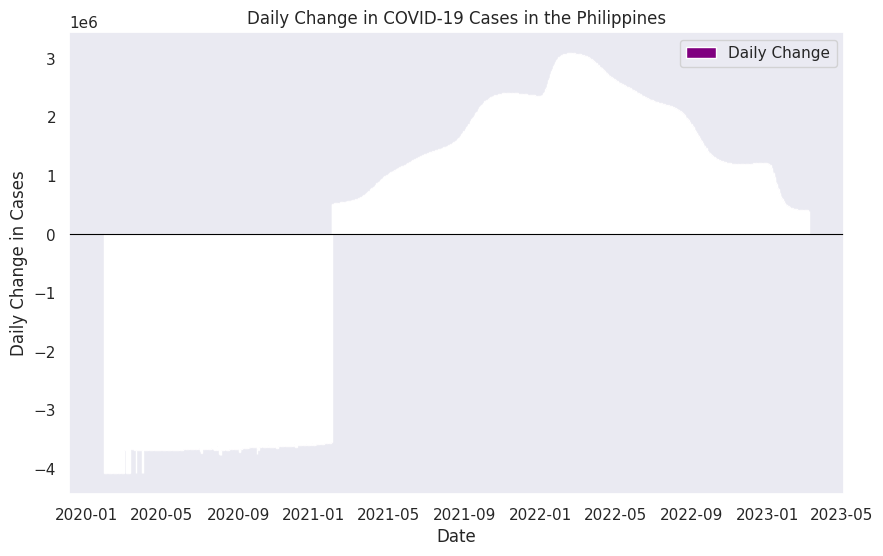

In [110]:
#Daily Change in Cases
country_data_eda["Daily Change"] = country_data_eda["Philippines"].diff()

plt.figure(figsize=(10, 6))
plt.bar(country_data_eda.index, country_data_eda["Daily Change"], color="purple", label="Daily Change")
plt.title("Daily Change in COVID-19 Cases in the Philippines")
plt.xlabel("Date")
plt.ylabel("Daily Change in Cases")
plt.axhline(0, color="black", linewidth=0.8)
plt.legend()
plt.grid()
plt.show()

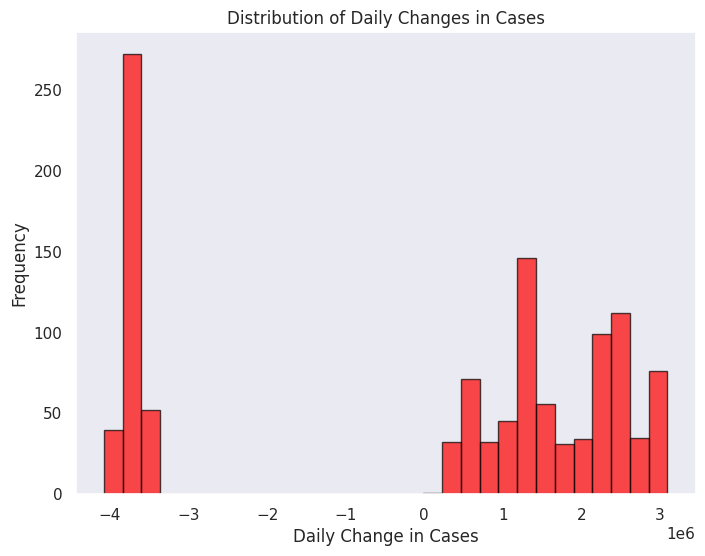

In [111]:
#Distribution of Daily Changes
plt.figure(figsize=(8, 6))
plt.hist(country_data_eda["Daily Change"].dropna(), bins=30, color="red", alpha=0.7, edgecolor="black")
plt.title("Distribution of Daily Changes in Cases")
plt.xlabel("Daily Change in Cases")
plt.ylabel("Frequency")
plt.grid()
plt.show()

In [112]:
#Stationarity Check (Augmented Dickey-Fuller Test)
from statsmodels.tsa.stattools import adfuller

adf_test = adfuller(country_data["Philippines"])
print("\nAugmented Dickey-Fuller Test Results:")
print(f"ADF Statistic: {adf_test[0]}")
print(f"p-value: {adf_test[1]}")
print("Critical Values:")
for key, value in adf_test[4].items():
    print(f"\t{key}: {value}")
if adf_test[1] <= 0.05:
    print("\nConclusion: The time series is stationary (p-value <= 0.05).")
else:
    print("\nConclusion: The time series is not stationary (p-value > 0.05).")

# Seasonal Decomposition (Optional)
#from statsmodels.tsa.seasonal import seasonal_decompose

#decomposition = seasonal_decompose(country_data["Philippines"], model="additive", period=30)
#decomposition.plot()
#plt.suptitle("Seasonal Decomposition of COVID-19 Cases in the Philippines")
#plt.show()


Augmented Dickey-Fuller Test Results:
ADF Statistic: -2.1644862458247656
p-value: 0.21938637278862017
Critical Values:
	1%: -3.4362020989495545
	5%: -2.864124028818559
	10%: -2.5681458107461737

Conclusion: The time series is not stationary (p-value > 0.05).


In [113]:
scaler = MinMaxScaler(feature_range=(0, 1))
country_data_scaled = scaler.fit_transform(country_data)


In [114]:
#Create Sequences for LSTM
def create_sequences(data, sequence_length):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i + sequence_length])
        y.append(data[i + sequence_length])
    return np.array(X), np.array(y)

In [115]:
sequence_length = 10
X, y = create_sequences(country_data_scaled, sequence_length)

# Split into Train/Test Sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Reshape Data for LSTM
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

In [116]:
def build_lstm_model(input_shape):
    model = Sequential([
        LSTM(64, return_sequences=True, input_shape=input_shape),
        Dropout(0.2),
        LSTM(32, return_sequences=False),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1)  # Output layer for regression
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

model = build_lstm_model((X_train.shape[1], X_train.shape[2]))

/opt/conda/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [117]:
# Train the Model
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 0.3238 - mae: 0.4592 - val_loss: 0.1800 - val_mae: 0.3928
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1482 - mae: 0.3444 - val_loss: 0.1704 - val_mae: 0.3872
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1511 - mae: 0.3493 - val_loss: 0.1703 - val_mae: 0.3872
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1510 - mae: 0.3473 - val_loss: 0.1632 - val_mae: 0.3768
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1485 - mae: 0.3467 - val_loss: 0.1626 - val_mae: 0.3786
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1432 - mae: 0.3401 - val_loss: 0.1619 - val_mae: 0.3795
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1529 - mae: 0.3556 - val_loss: 0.1608 - val_mae: 0.3781
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1440 - mae: 0.3434 - val_loss: 0.1578 - val_mae: 0.3740
Epoch 9/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.146

In [118]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Loss: {test_loss}, Test MAE: {test_mae}")


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0114 - mae: 0.0411 
Test Loss: 0.00630953861400485, Test MAE: 0.036171335726976395


In [119]:
# Make Predictions
y_pred = model.predict(X_test)

# Inverse Transform Predictions for Comparison
y_test_scaled = scaler.inverse_transform(y_test.reshape(-1, 1))
y_pred_scaled = scaler.inverse_transform(y_pred)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step


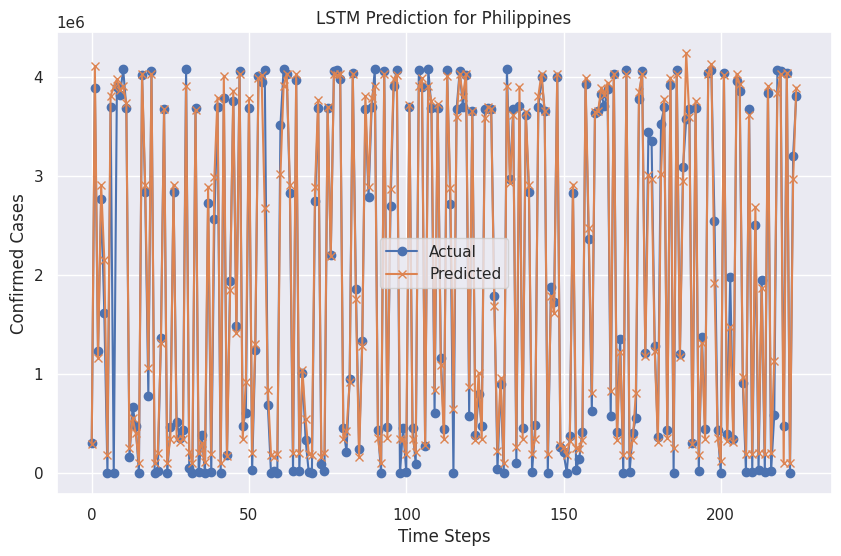

In [120]:
# Visualization
plt.figure(figsize=(10, 6))
plt.plot(y_test_scaled, label="Actual", marker='o')
plt.plot(y_pred_scaled, label="Predicted", marker='x')
plt.title(f"LSTM Prediction for {country}")
plt.xlabel("Time Steps")
plt.ylabel("Confirmed Cases")
plt.legend()
plt.show()

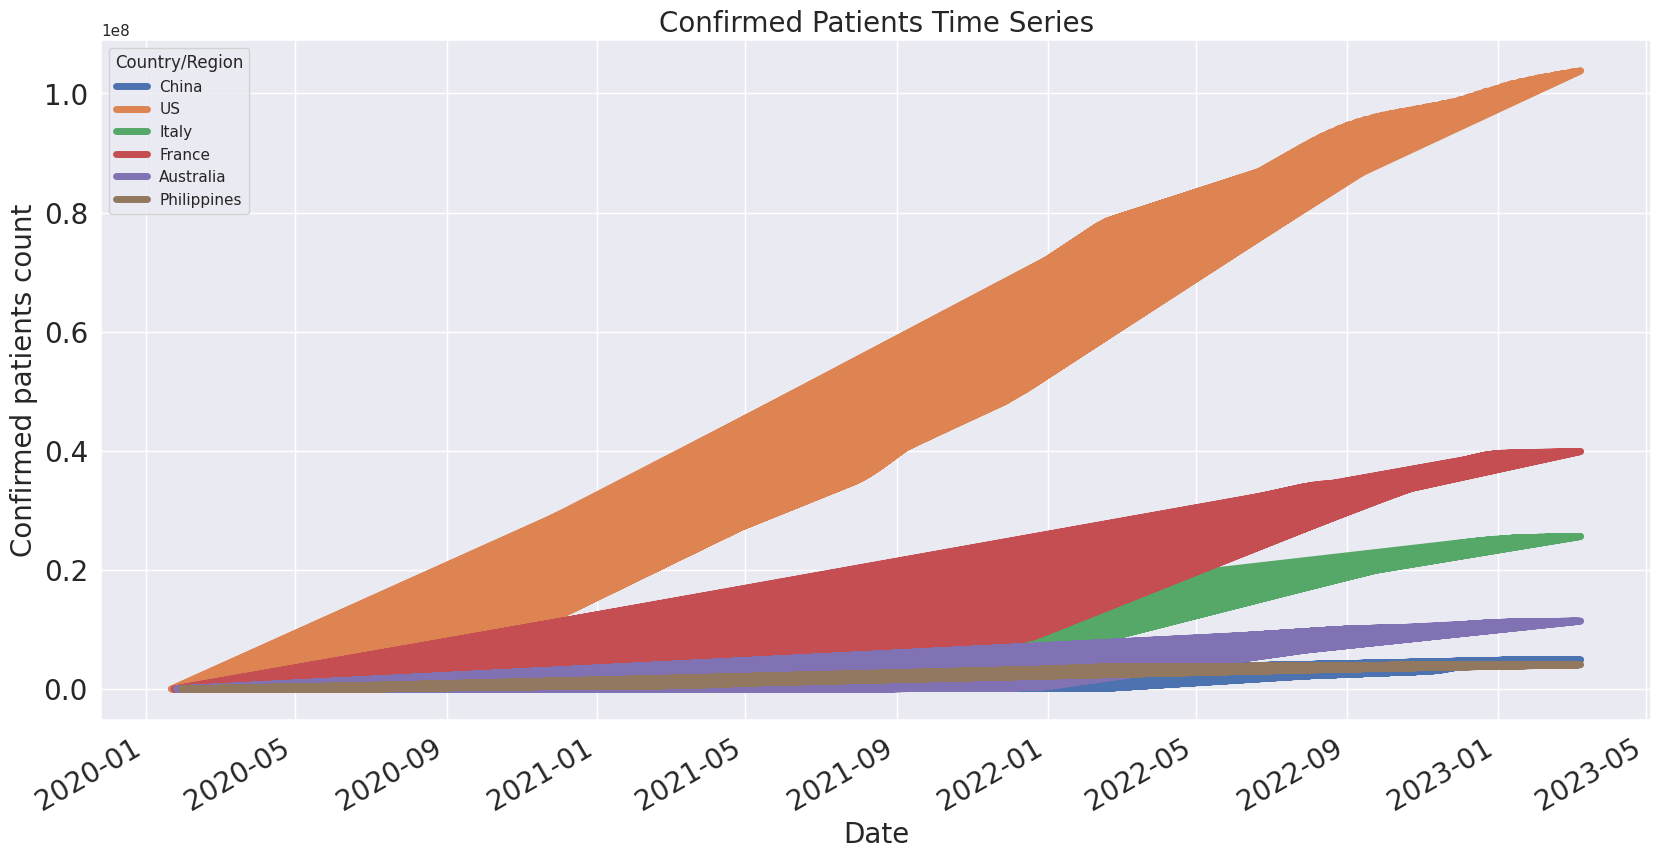

In [121]:
# Plot time series of several countries of interest
poi = ['China', 'US', 'Italy', 'France', 'Australia','Philippines']
df[poi].plot(figsize=(20,10), linewidth=5, fontsize=20)
plt.xlabel('Date', fontsize=20);
plt.ylabel('Confirmed patients count', fontsize=20);
plt.title('Confirmed Patients Time Series', fontsize=20);

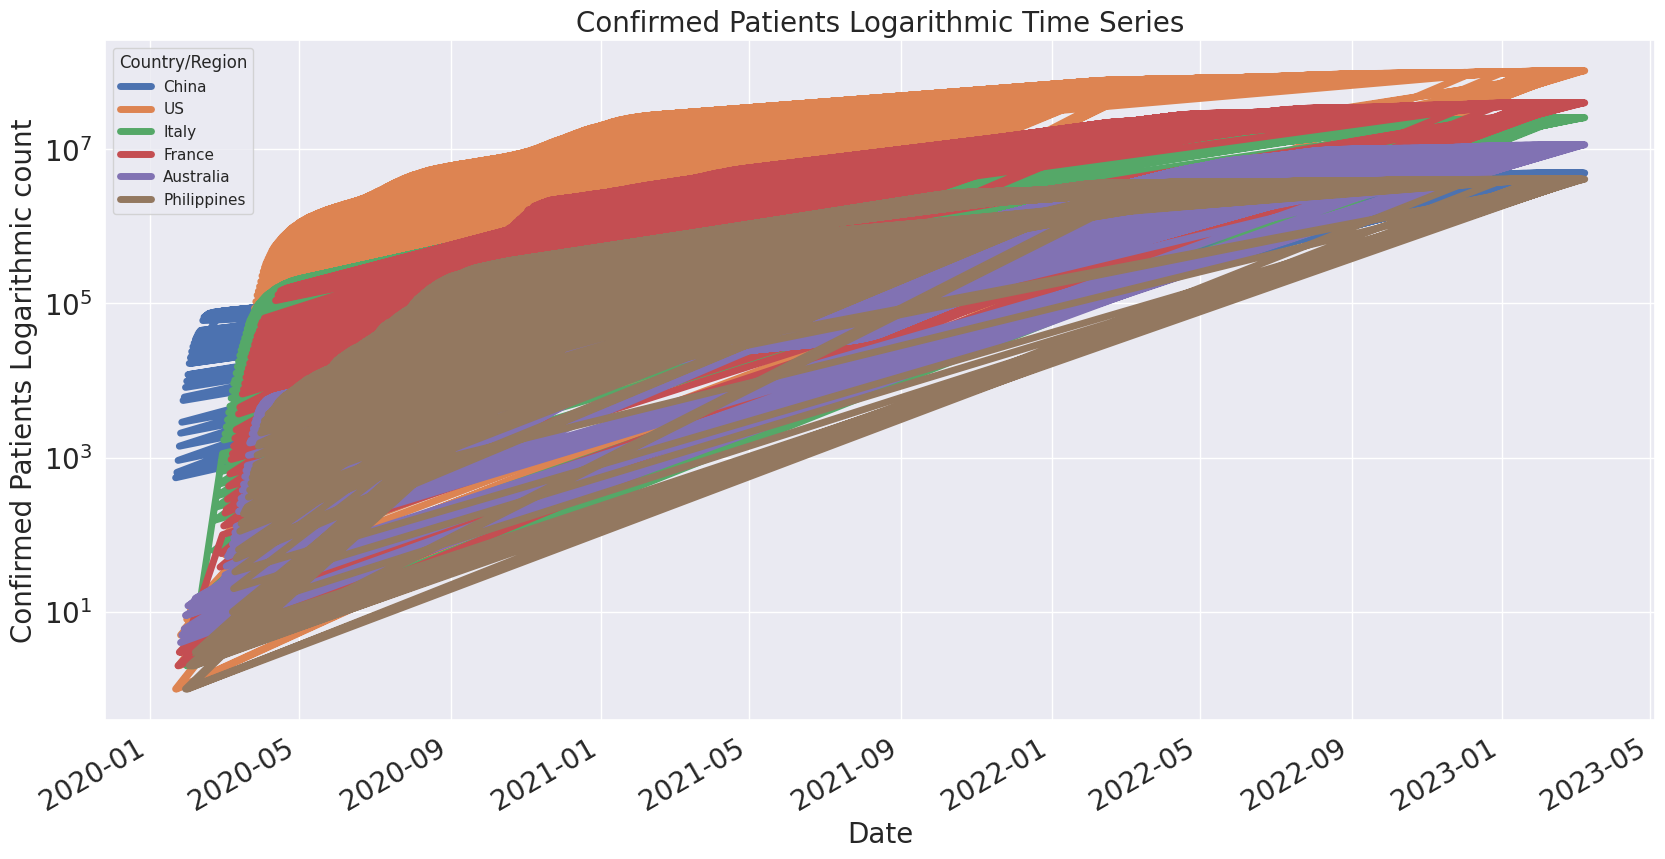

In [122]:
# Plot time series of several countries of interest
poi = ['China', 'US', 'Italy', 'France', 'Australia','Philippines']
df[poi].plot(figsize=(20,10), linewidth=5, fontsize=20, logy=True)
plt.xlabel('Date', fontsize=20);
plt.ylabel('Confirmed Patients Logarithmic count', fontsize=20);
plt.title('Confirmed Patients Logarithmic Time Series', fontsize=20);